In [13]:
import sys
sys.path.append('../src')

In [12]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torchvision import transforms
from utils import ImageDatasetFromFolders
from torch.utils.data import Dataset, DataLoader
from train_test_utils import train_model, test_model
from plotting import plot_learning_curves
from utils import NeuralNetwork
from torch import nn
from config import ProjectConfig

In [2]:
config = ProjectConfig()

In [3]:
SEED = 123

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)
base = os.getcwd()

train_dir = os.path.join(base, "Train")
val_dir = os.path.join(base, "Validation")
test_dir = os.path.join(base, "Test")

# lower resolution for now - testing purposes
image_size = (64, 64)
batch_size = 32

transform = transforms.Compose([transforms.Resize(image_size),transforms.ToTensor()])

Using device: cpu


In [4]:
from utils import ImageDatasetFromFolders

train_data = ImageDatasetFromFolders(train_dir, transform)
val_data = ImageDatasetFromFolders(val_dir, transform)
test_data = ImageDatasetFromFolders(test_dir, transform)

print("Classes:", train_data.class_names)
print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Test images:", len(test_data))

assert (train_data.class_names == val_data.class_names == test_data.class_names)

train_dl = DataLoader(train_data,batch_size=batch_size,shuffle=True)

val_dl = DataLoader(val_data,batch_size=batch_size,shuffle=False)

test_dl = DataLoader(test_data,batch_size=batch_size,shuffle=False)

Classes: ['Healthy', 'Powdery', 'Rust']
Training images: 1322
Validation images: 60
Test images: 150


In [5]:
model = NeuralNetwork(num_classes=3).to(device)

print(model)
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(model.parameters(),lr=0.0001,weight_decay=5e-4)

NeuralNetwork(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=12288, out_features=512, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=512, out_features=128, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.3, inplace=False)
    (7): Linear(in_features=128, out_features=3, bias=True)
  )
)


In [6]:
history, training_time = train_model(model, test_dl, val_dl, criterion, optimizer, device, config, save_files=True, num_epochs=10)

relevant directories created ... 
Epoch [1/10] | Train Loss: 1.4542 | Train Acc: 0.2733 | Val Loss: 1.1090 | Val Acc: 0.3833
Epoch [2/10] | Train Loss: 1.1070 | Train Acc: 0.2800 | Val Loss: 1.0956 | Val Acc: 0.3500
Epoch [3/10] | Train Loss: 1.0983 | Train Acc: 0.3867 | Val Loss: 1.0974 | Val Acc: 0.3333
Epoch [4/10] | Train Loss: 1.1231 | Train Acc: 0.2867 | Val Loss: 1.0997 | Val Acc: 0.4667
Epoch [5/10] | Train Loss: 1.1337 | Train Acc: 0.3000 | Val Loss: 1.1006 | Val Acc: 0.3333
Epoch [6/10] | Train Loss: 1.1094 | Train Acc: 0.3333 | Val Loss: 1.1018 | Val Acc: 0.3333
Epoch [7/10] | Train Loss: 1.1018 | Train Acc: 0.3733 | Val Loss: 1.1026 | Val Acc: 0.3333
Epoch [8/10] | Train Loss: 1.1085 | Train Acc: 0.3800 | Val Loss: 1.1017 | Val Acc: 0.3333
Epoch [9/10] | Train Loss: 1.1074 | Train Acc: 0.3533 | Val Loss: 1.1009 | Val Acc: 0.3333
Epoch [10/10] | Train Loss: 1.1005 | Train Acc: 0.3533 | Val Loss: 1.0994 | Val Acc: 0.3333


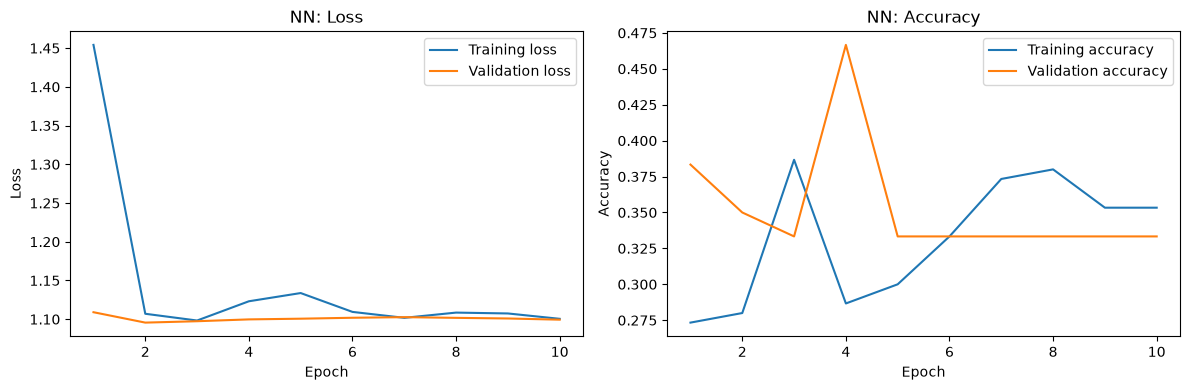

In [8]:
plot_learning_curves(history, config, file_name='pytorch_nn_disease_recognition_learning_curve')

relevant directories created ... 
Test loss: 1.0871
Test accuracy: 0.3333
----------------------------------------
Classification Report
----------------------------------------


              precision    recall  f1-score   support

     Healthy       0.00      0.00      0.00        50
     Powdery       0.00      0.00      0.00        50
        Rust       0.33      1.00      0.50        50

    accuracy                           0.33       150
   macro avg       0.11      0.33      0.17       150
weighted avg       0.11      0.33      0.17       150



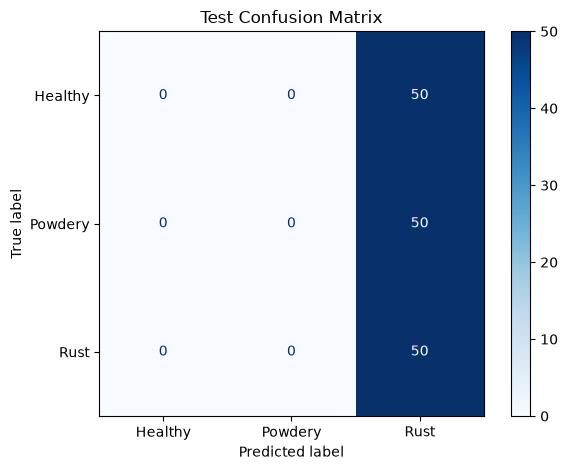

In [10]:
history = torch.load(f"{config.model_dir}/pytorch_nn_history.pt")
# print(history)
state_dict = torch.load(f"{config.model_dir}/pytorch_nn_state_dict.pth")
loaded_model = NeuralNetwork()
loaded_model.load_state_dict(state_dict)
# print(loaded_model)

test_loss, test_accuracy, all_predictions, all_labels, cm = test_model(loaded_model, test_dl, criterion, train_data.class_names, device, config, file_name='confusion_matrix', plot_confusion_matrix=True)